# 01 — Telemetria, simulador e qualidade dos dados

**Objetivo.** Entender o modelo canônico de telemetria do AgroFleet, gerar a frota **simulada** (4 pulverizadores) e passar dados "sujos" pelos adaptadores e pelo relatório de qualidade.

> ⚠️ **Tudo neste notebook é SIMULADO** (`origin="simulated"`). Local, talhões, códigos de erro e números são fictícios. Nenhum resultado aqui descreve uma máquina real.

**O que você vai conseguir verificar ao final**
1. Campos opcionais ausentes aparecem como `None`/`NaN`, nunca como `0` inventado.
2. O simulador é determinístico (mesma semente → mesmos bytes) e registra uma *verdade-terreno* dos eventos injetados.
3. Os adaptadores contam e explicam cada linha rejeitada; o relatório de qualidade aponta duplicatas, lacunas, saltos e suspeita de unidade.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from agrofleet.schema import TelemetryPoint, SCHEMA_VERSION
from agrofleet.simulator.fleet import simulate
from agrofleet.analytics.frame import to_frame
from agrofleet import adapters as AD
from agrofleet.quality import assess
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("schema", SCHEMA_VERSION)

schema 1.0


## 1. O modelo canônico e as regras que ele impõe

**O quê.** `TelemetryPoint` (pydantic) descreve *o que a máquina reportou* — não o que é verdade. Campos: `machine_id`, `ts` (UTC com fuso), `lat/lon`, `speed_ms`, `state`, `gnss_fix`, `accuracy_m`, `flow_lpm`, `pressure_bar`, `tank_level_l`, `consumption_l`, `working_width_m`, `application_rate_lha`, `error_codes`, `sensor_quality` por sensor, e metadados opcionais (`property_id`, `field_id`, `operator_id`).

**Por quê.** A regra central é *ausente ≠ zero*. Uma vazão `0` diz "o sensor mediu zero"; `None` diz "não sei". Misturar os dois produz médias erradas e alertas falsos. Por isso a validação rejeita `NaN/Inf`, coordenada `(0,0)` (valor-padrão típico de receptor sem fix), `lat` sem `lon`, e *timestamp sem fuso*.

**Alternativas.** (a) Preencher com último valor conhecido (*forward fill*) — esconde perda de sinal; (b) usar `0` — confunde medição e ausência; (c) esquema livre (dict) — empurra a validação para cada consumidor. Escolhemos validar na borda.

**Como verificar.** As células abaixo tentam criar pontos inválidos e mostram o erro.

In [2]:
tests = {
  "sem fuso": dict(ts="2026-03-10T10:00:00"),
  "(0,0)": dict(ts="2026-03-10T10:00:00Z", lat=0.0, lon=0.0),
  "lat sem lon": dict(ts="2026-03-10T10:00:00Z", lat=-16.7),
  "NaN": dict(ts="2026-03-10T10:00:00Z", flow_lpm=float("nan")),
  "campo extra": dict(ts="2026-03-10T10:00:00Z", comando="parar"),
}
for nome, kw in tests.items():
    try:
        TelemetryPoint(machine_id="M1", **kw); print(f"{nome:12s} -> ACEITO (inesperado)")
    except ValueError as e:
        err = e.errors()[0]
        print(f"{nome:12s} -> rejeitado ({'.'.join(map(str, err['loc'])) or 'modelo'}): {err['msg'][:80]}")
p = TelemetryPoint(machine_id="M1", ts="2026-03-10T07:00:00-03:00")
print("\nUTC normalizado:", p.ts, "| flow:", p.flow_lpm, "| lat:", p.lat, "| state:", p.state.value)

sem fuso     -> rejeitado (ts): Value error, timestamp sem fuso horário (esperado UTC explícito)
(0,0)        -> rejeitado (modelo): Value error, coordenada (0,0) rejeitada: valor-padrão típico de receptor sem fix
lat sem lon  -> rejeitado (modelo): Value error, lat e lon devem vir juntos (ambos ou nenhum)
NaN          -> rejeitado (flow_lpm): Input should be greater than or equal to 0
campo extra  -> rejeitado (comando): Extra inputs are not permitted

UTC normalizado: 2026-03-10 10:00:00+00:00 | flow: None | lat: None | state: unknown


**Como ler a saída.** Todos os casos inválidos devem aparecer como *rejeitado*. O último print mostra o horário `-03:00` convertido para UTC (10:00) e os opcionais em `None`. O caso `campo extra` (`comando`) é rejeitado de propósito: o esquema **não tem** campo de comando — `extra="forbid"` impede que alguém "contrabandeie" instruções de controle num payload de telemetria.

## 2. O simulador de 4 pulverizadores

**O quê.** Quatro máquinas, cada uma num talhão retangular de 20 ha, com passadas paralelas (*boustrophedon*), barra de 24 m e taxa nominal de 100 L/ha. Cenários injetados:

| Máquina | Cenário | O que acontece |
|---|---|---|
| SIM-01 | normal | passadas a 22 m (sobreposição nominal de 8,3%) |
| SIM-02 | `stop` | parada por falha simulada de 7 min (código fictício `SIM-E042`) |
| SIM-03 | `gnss_loss` + `missing_data` | 4 min sem GNSS, depois 2 min de reconvergência RTK-float; 2,5 min sem vazão/pressão (em outro momento) |
| SIM-04 | `abnormal_flow` | vazão 35% abaixo do esperado por 5 min (causa **não** modelada) |

**Por quê.** Sem verdade conhecida não dá para testar nada de forma honesta. Aqui a verdade é analítica: áreas planejadas, sobreposição nominal e janelas dos eventos.

**Limites.** É um modelo simples (velocidade suavizada, ruído gaussiano, vazão = taxa × velocidade × largura). Não tem vento, relevo, terraços, curvas de nível, falhas realistas de bico ou latência de rede.

In [3]:
pts, truth = simulate(seed=7)
df = to_frame(pts)
pts2, _ = simulate(seed=7)
print("pontos:", len(pts), "| determinístico:", [p.model_dump_json() for p in pts] == [p.model_dump_json() for p in pts2])
print("origens:", list(df.origin.unique()), "| máquinas:", sorted(df.machine_id.unique()))
print(df.groupby("machine_id").agg(amostras=("ts","size"), inicio=("ts","min"), fim=("ts","max")).to_string())
print("\nEventos injetados (verdade-terreno):")
print(pd.DataFrame(truth.events)[["machine_id","type","start","end"]].to_string(index=False))

pontos: 11331 | determinístico: True
origens: ['simulated'] | máquinas: ['SIM-01', 'SIM-02', 'SIM-03', 'SIM-04']
            amostras                    inicio                       fim
machine_id                                                              
SIM-01          2628 2026-03-10 10:00:00+00:00 2026-03-10 10:43:47+00:00
SIM-02          3237 2026-03-10 10:00:00+00:00 2026-03-10 10:53:56+00:00
SIM-03          2349 2026-03-10 10:00:00+00:00 2026-03-10 10:39:08+00:00
SIM-04          3117 2026-03-10 10:00:00+00:00 2026-03-10 10:51:56+00:00

Eventos injetados (verdade-terreno):
machine_id          type                     start                       end
    SIM-02          stop 2026-03-10T10:10:30+00:00 2026-03-10T10:17:30+00:00
    SIM-03     gnss_loss 2026-03-10T10:08:30+00:00 2026-03-10T10:12:30+00:00
    SIM-03  missing_data 2026-03-10T10:03:24+00:00 2026-03-10T10:05:54+00:00
    SIM-04 abnormal_flow 2026-03-10T10:14:15+00:00 2026-03-10T10:19:15+00:00


**Como ler a saída.** `determinístico: True` confirma reprodutibilidade (importante para testes). As quatro máquinas terminam o talhão em tempos diferentes porque o número de reabastecimentos, paradas e deslocamentos difere. A tabela de eventos é a *verdade* que usaremos nos notebooks seguintes para medir detecção — e que o sistema de detecção **não enxerga**.

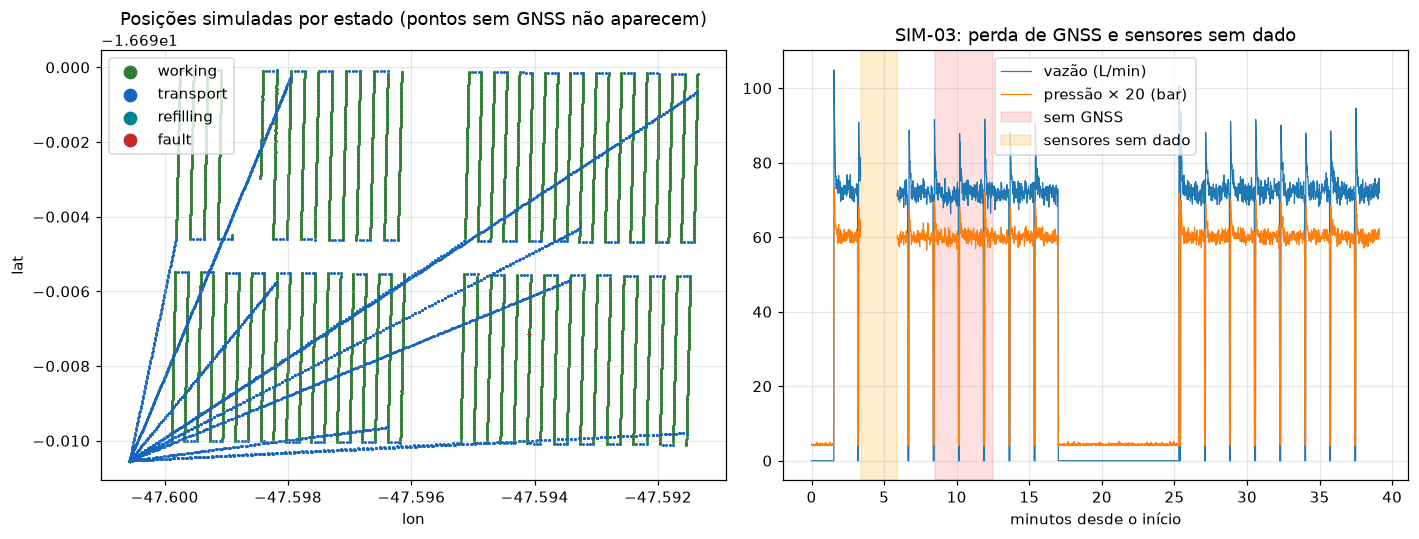

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cores = {"working":"#2e7d32","transport":"#1565c0","refilling":"#00838f","fault":"#c62828"}
for mid, g in df.groupby("machine_id"):
    gg = g.dropna(subset=["lat"])
    for st, c in cores.items():
        s = gg[gg.state == st]
        ax[0].scatter(s.lon, s.lat, s=1, c=c, label=st if mid == "SIM-01" else None)
ax[0].set_title("Posições simuladas por estado (pontos sem GNSS não aparecem)"); ax[0].set_xlabel("lon"); ax[0].set_ylabel("lat"); ax[0].legend(markerscale=8)
g = df[df.machine_id == "SIM-03"].copy(); g["min"] = (g.ts - g.ts.min()).dt.total_seconds() / 60
ax[1].plot(g["min"], g.flow_lpm, lw=.8, label="vazão (L/min)"); ax[1].plot(g["min"], g.pressure_bar * 20, lw=.8, label="pressão × 20 (bar)")
perda = g[g.lat.isna()]; ax[1].axvspan(perda["min"].min(), perda["min"].max(), color="red", alpha=.12, label="sem GNSS")
nulo = g[g.flow_lpm.isna()]; ax[1].axvspan(nulo["min"].min(), nulo["min"].max(), color="orange", alpha=.2, label="sensores sem dado")
ax[1].set_title("SIM-03: perda de GNSS e sensores sem dado"); ax[1].set_xlabel("minutos desde o início"); ax[1].legend()
plt.tight_layout(); plt.show()

**Como ler os gráficos.** À esquerda, quatro talhões (A–D) com passadas verdes (trabalho) e as linhas azuis longas de deslocamento até o depósito (canto inferior esquerdo; os tracinhos azuis nas pontas das passadas são as manobras de cabeceira). No talhão do alto à esquerda (SIM-03) **faltam passadas inteiras**: são os pontos sem GNSS, que simplesmente não existem no gráfico — o sistema não "completa" a trajetória.

À direita, o SIM-03. A faixa vermelha é o intervalo **sem posição** (min 8,5–12,5); a laranja, o intervalo **sem vazão/pressão** (min ~3,4–5,9) — nesses trechos as curvas *quebram*, não há linha ligando os pontos. Três coisas para não confundir com defeito: (1) cada passada começa com um **pico de vazão** (~100 L/min contra ~72 nominais) porque o simulador entra na passada mais rápido do que a velocidade de trabalho e a vazão de um controlador de taxa acompanha a velocidade (vazão = taxa × velocidade × largura); (2) o trecho plano entre os minutos ~17 e ~25 é a viagem ao depósito e o reabastecimento (vazão zero, pressão baixa); (3) a máquina continua trabalhando durante a perda de GNSS, mas o sistema não sabe *onde* — situação que a análise de cobertura precisa tratar com honestidade (notebook 02).

## 3. Adaptadores: CSV "sujo" e relatório de qualidade

**O quê.** O adaptador CSV mapeia colunas por *aliases* explícitos e converte unidades (ex.: `km/h→m/s`, `kPa→bar`). Cada linha rejeitada é contada com o motivo. O relatório de qualidade (`assess`) acusa duplicatas, ordem, lacunas, saltos de posição e suspeita de unidade.

**Por quê.** Arquivos reais chegam com colunas em português, unidades misturadas, horários sem fuso e linhas quebradas. Em vez de "consertar em silêncio", o sistema **mostra o que fez** (`meta.columns_mapped`, `units`, `columns_ignored`).

**Alternativas.** Inferir unidade pela magnitude (arriscado: 18 pode ser km/h ou m/s) — só aceitamos inferência pelo *nome* da coluna (`speed_kmh`) e registramos o aviso.

In [5]:
sujo = (
 "machine,time,lat,lon,speed_kmh,pressure,flow,state\n"
 "M1,2026-03-10T10:00:00Z,-16.7,-47.6,18,300,70,spraying\n"
 "M1,2026-03-10T10:00:00Z,-16.7,-47.6,18,300,70,spraying\n"      # duplicada
 "M1,2026-03-10T10:05:00Z,-16.7,-47.6,60,300,70,spraying\n"      # lacuna de 5 min + velocidade alta
 "M1,2026-03-10T10:00:30Z,-16.7,-47.6,18,300,70,spraying\n"      # fora de ordem
 "M1,2026-03-10T10:05:01Z,-16.6,-47.6,18,300,70,spraying\n"      # salto de ~11 km em 1 s
 "M1,2026-03-10 10:05:02,-16.6,-47.6,18,300,70,spraying\n"       # sem fuso
 "M1,2026-03-10T10:05:03Z,0,0,18,300,70,spraying\n")             # (0,0)
r = AD.read_csv(sujo, units={"pressure": "kPa"}, origin="simulated")
print("válidas:", len(r.points), "| rejeitadas:", r.n_rejected_total)
for x in r.rejected: print("  linha", x["row"], "->", x["reason"][:100])
print("avisos:", r.warnings)
print("mapeamento:", r.meta["columns_mapped"])
q = assess(r)
print("\nveredito:", q["verdict"])
for f in q["flags"]: print(f"  [{f['level']}] {f['code']}: {f['msg']}")

válidas: 5 | rejeitadas: 2
  linha 6 -> timestamp sem fuso horário (informe assume_tz, ex.: 'UTC' ou 'America/Sao_Paulo')
  linha 7 -> : Value error, coordenada (0,0) rejeitada: valor-padrão típico de receptor sem fix
avisos: ["coluna 'speed_kmh': unidade km/h deduzida do NOME da coluna"]
mapeamento: {'machine_id': 'machine', 'ts': 'time', 'lat': 'lat', 'lon': 'lon', 'speed': 'speed_kmh', 'state': 'state', 'flow': 'flow', 'pressure': 'pressure'}

veredito: warnings
  [warn] duplicates: 1 linhas com (machine_id, ts) repetido
  [warn] out_of_order: 1 amostras fora de ordem cronológica no arquivo (reordenadas na análise)
  [warn] position_jumps: M1: 1 saltos de posição (> 40.0 m/s implícitos)
  [warn] gaps: M1: 1 lacunas > 30 s (270 s no total)


**Como ler a saída.** Esperamos: 2 linhas rejeitadas (*sem fuso* e *(0,0)*), com motivo; o aviso de que `speed_kmh` teve a unidade deduzida do **nome**; e no relatório os avisos `duplicates`, `out_of_order`, `position_jumps` e `gaps`. O aviso `unit_suspect` **não** dispara aqui, e é o esperado: 60 km/h (16,7 m/s) fica abaixo do limite de 25 m/s e 300 kPa = 3 bar é plausível; ele só aparece quando a magnitude é implausível para a unidade declarada. O veredito `warnings` significa "dá para usar, mas leia os avisos"; `blocking` significa "nada foi aproveitável".

**O que isso NÃO garante.** O relatório detecta inconsistências *internas*. Não consegue saber se um dado "real" foi de fato coletado por uma máquina — por isso `origin="real"` é só uma **declaração** de quem enviou.

In [6]:
# O formato JSON (envelope MQTT versionado) também passa pelo mesmo caminho de validação
from agrofleet.schema import wrap
env = [wrap(pts[0], "a"), {**wrap(pts[1], "b"), "schema_version": "2.0"}]
r2 = AD.read_json(json.dumps(env))
print("envelopes aceitos:", len(r2.points), "| rejeitados:", r2.n_rejected_total, "->", r2.rejected[0]["reason"][:80])
print("ISOXML:", AD.REGISTRY["isoxml"]); print("REST de fabricante:", AD.REGISTRY["manufacturer_rest"])
try: AD.read_isoxml(b"<x/>")
except AD.NotImplementedAdapter as e: print("\nisoxml ->", e)

envelopes aceitos: 1 | rejeitados: 1 -> envelope inválido: Value error, versão de schema incompatível: 2.0 (suportado: 1
ISOXML: {'status': 'not_implemented', 'tested': False, 'note': 'sem amostra válida nem parser validado'}
REST de fabricante: {'status': 'not_implemented', 'tested': False, 'note': 'nenhuma API de fabricante documentada foi usada; nenhuma integração inventada'}

isoxml -> ISOXML/TASKDATA não implementado: sem amostra TASKDATA/TLG válida e sem parser validado; ver docs/GUIA_TECNICO.md (seção 5.6)


**Como ler a saída.** O envelope com `schema_version: 2.0` é recusado — não adivinhamos o significado de uma versão futura. ISOXML e API de fabricante aparecem como **não implementados**, com o motivo: não havia amostra válida de `TASKDATA`/`TLG` nem documentação de API para validar. Preferimos não entregar um parser que *parece* funcionar sem teste real.

## Resumo e próximos passos
- O modelo canônico transforma "ausente" em `None` e rejeita inconsistências na borda.
- O simulador entrega verdade conhecida; os adaptadores e o relatório de qualidade explicam cada rejeição.
- **Próximo:** notebook 02 — geometria de cobertura (área bruta × única × sobreposição) e métricas operacionais.